# 04 小程序 - 基础加强


本篇是微信小程序基础第 04 天，按原讲义顺序整理：组件的创建与引用 → 样式隔离 → 数据、方法和属性 → 数据监听器与 RGB 调色 → 纯数据字段 → 组件及所在页面的生命周期 → 插槽 → 父子通信 → behaviors。

资料依据：[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234) 中的微信小程序基础 `day04.rar`，包括《00_小程序 - 基础加强》58 页正文讲义、4 页目标讲义、`学习目标.txt`、`代码.rar` 与 `资料.rar`。目标页和目录沿用“基础加强”的总纲，本天正文实际讲到自定义组件与 behaviors，以下以当天正文和学习目标为准。

`资料.rar` 提供起始项目 `mp_04`，`代码.rar` 提供完成后的同名项目。在微信开发者工具中导入项目，使用自己的 AppID。

| 配套位置 | 本天用途 |
| --- | --- |
| `components/test/test.*` | 组件引用、样式隔离、计数与 `max` 属性 |
| `components/test2/test2.*` | 监听 `n1`、`n2`，计算 `sum` |
| `components/test3/test3.*` | RGB 调色、纯数据字段和生命周期 |
| `components/test4/test4.*` | 单个与多个插槽 |
| `components/test5/test5.*` | 父子计数同步、获取实例与 behavior |
| `pages/home/home.*`、`app.json` | 承载组件及配置引用 |
| `behaviors/my-behavior.js` | 共享的 `username` 数据 |

完成版 `home.wxml` 只启用了 `my-test5`，早期组件标签被注释。分步练习时，按当前章节启用对应标签；代码围栏中的片段需合并到指定文件的现有节点中，保留其他配置。所有代码均用于阅读和复制，不使用可执行单元。


## 一、组件的创建与引用

自定义组件把一块 UI、它的数据和交互封装在一起，便于在不同页面复用。

### 1. 创建组件

在微信开发者工具的项目目录中操作：

1. 在项目根目录新建 `components` 文件夹，再创建 `components/test`。
2. 右键 `test` 文件夹，选择“新建 Component”。
3. 输入组件名称 `test`，回车，生成 `test.js`、`test.json`、`test.wxml`、`test.wxss`。

不同组件放进各自目录，配套项目中的结构是：

```text
mp_04/
├─ components/
│  ├─ test/       → test.js、test.json、test.wxml、test.wxss
│  ├─ test2/      → test2.js、test2.json、test2.wxml、test2.wxss
│  ├─ test3/      → test3.js、test3.json、test3.wxml、test3.wxss
│  ├─ test4/      → test4.js、test4.json、test4.wxml、test4.wxss
│  └─ test5/      → test5.js、test5.json、test5.wxml、test5.wxss
├─ behaviors/
│  └─ my-behavior.js
├─ pages/
└─ app.json
```

### 2. 组件和页面的区别

两者都有四类文件，但 JavaScript 和 JSON 的声明不同：

| 对比项 | 页面 | 自定义组件 |
| --- | --- | --- |
| 注册函数 | `Page()` | `Component()` |
| `.json` 声明 | 页面配置 | 需要 `"component": true` |
| 事件处理函数 | 本课放在 `Page` 配置对象中 | 放在 `methods` 节点中 |

`components/test/test.json`：

```json
{
  "component": true,
  "usingComponents": {}
}
```

生成四类文件后，还需要先引用，页面才能通过组件标签使用它。


### 3. 局部引用

在页面的 `.json` 中配置 `usingComponents`，组件只在该页面内使用。以 `pages/home/home.json` 为例：

```json
{
  "usingComponents": {
    "my-test1": "/components/test/test"
  }
}
```

在 `pages/home/home.wxml` 中使用配置的名称：

```xml
<my-test1></my-test1>
```

`my-test1` 是自定义标签名；路径从小程序根目录开始，不加 `.js` 或 `.wxml` 后缀。

资料差异：讲义第 5 页用 `/components/test1/test1` 演示命名；实际压缩包中的第一组组件位于 `/components/test/test`。本篇按配套文件的真实路径写，不能把讲义示意路径原样填进现有项目。


### 4. 全局引用

在 `app.json` 中配置 `usingComponents`，各页面即可使用对应组件。配套完成版在根级注册了五个组件，以下是要合并到 `app.json` 的字段：

```json
{
  "usingComponents": {
    "my-test1": "/components/test/test",
    "my-test2": "/components/test2/test2",
    "my-test3": "/components/test3/test3",
    "my-test4": "/components/test4/test4",
    "my-test5": "/components/test5/test5"
  }
}
```

保留 `app.json` 已有的 `pages`、`window`、`tabBar`、`style` 和 `sitemapLocation`，不要用上述片段替换整个文件。

例如，在首页依次练习监听器或 RGB 案例时，启用其中一个标签：

```xml
<my-test2></my-test2>
```

```xml
<my-test3></my-test3>
```

原课的选择原则：多个页面经常使用的组件适合全局引用；仅在特定页面使用的组件适合局部引用。两种写法是可选的引用方式，不要求同一组件在两处重复声明。

验证引用是否成功：当前页面应显示对应组件的内容；若标签没有显示，先检查 `usingComponents` 的位置、标签名称和路径，再检查 WXML 标签是否仍在注释中。


## 二、组件样式隔离

默认情况下，使用 class 指定的组件样式在组件内生效。组件 A、组件 C 和页面使用相同类名，也不会因为这些类样式互相影响。这能防止外界样式干扰组件，也能防止组件样式破坏页面。

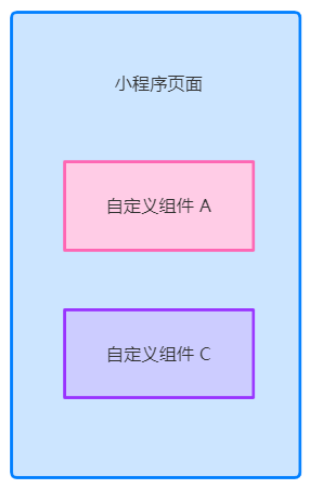

原课特别提醒：默认隔离下，`app.wxss` 中的全局 class 样式对组件内部无效；不要依赖 id、属性或标签选择器获得相同的隔离效果。**组件及引用组件的页面都建议使用 class 选择器。**


### 1. 修改 styleIsolation

如果需要从页面控制组件内部的类样式，可修改组件的样式隔离选项。

在组件 `.js` 的 `options` 中配置，讲义示例为：

```javascript
Component({
  options: {
    styleIsolation: 'isolated'
  }
})
```

讲义还演示了在组件 `.json` 中配置的方式，例如 `components/test/test.json`：

```json
{
  "component": true,
  "usingComponents": {},
  "styleIsolation": "isolated"
}
```

上述是两种配置位置。练习时选定一种，保留其他已有字段，并根据目标选择下面的值：

| 值 | 是否默认 | class 样式的影响方向 |
| --- | --- | --- |
| `isolated` | 是 | 页面与组件之间互不影响 |
| `apply-shared` | 否 | 页面 WXSS 可影响组件，组件 WXSS 不影响页面 |
| `shared` | 否 | 页面 WXSS 可影响组件；组件 WXSS 也可影响页面及其他设为 `apply-shared` 或 `shared` 的组件 |

后两种配置改变的是样式的作用范围，不能仅凭类名相同就假设仍互相隔离。


### 2. 用配套样式观察隔离效果

`app.wxss` 的全局类样式：

```css
.g-red-text {
  color: red;
}
```

`components/test/test.wxss` 的组件类样式：

```css
/* components/test/test.wxss */
.g-red-text {
  font-weight: bold;
}
```

在组件 `test.wxml` 内使用同一类名：

```xml
<text class="g-red-text">components/test/test.wxml</text>
```

页面也可以放一个 `class="g-red-text"` 的 `<text>` 对照。默认 `isolated` 时，组件内部应应用自己的加粗样式，外部全局红色 class 样式不会传入；把组件改为 `shared` 后，再观察组件文字的颜色。

配套完成版 `test.js` 已设置 `styleIsolation: 'shared'`，所以直接导入完成版看到的是共享状态。要验证默认隔离，需要先移除该设置或明确改成 `isolated`。


## 三、组件的数据、方法和属性

### 1. data 保存私有渲染数据

`data` 存放组件内部用于模板渲染的数据。计数示例从 `count: 0` 开始，通过 `setData` 更新视图。

### 2. methods 定义事件及自定义方法

讲义先演示增加 `count`，再通过一个内部方法显示计数。下面是这一阶段的 `components/test/test.js` 核心结构：

```javascript
Component({
  data: {
    count: 0
  },
  methods: {
    // 点击事件处理函数
    addCount() {
      this.setData({
        count: this.data.count + 1
      })
      this._showCount()
    },
    _showCount() {
      wx.showToast({
        title: 'count是' + this.data.count,
        icon: 'none'
      })
    }
  }
})
```

`components/test/test.wxml` 对应绑定：

```xml
<view>count的值是：{{count}}</view>
<button bindtap="addCount">+1</button>
```

点击后计数应增加，提示文字显示新的值。事件函数 `addCount` 与普通方法 `_showCount` 都在 `methods` 中；以下划线开头是本课用于区分内部方法的命名习惯。


### 3. properties 接收外界数据

组件的 `properties` 定义对外属性，用于接收页面或父组件传入的数据。讲义以 `max` 为例，给计数功能增加一个上限参数。

需要默认值时，用完整定义；合并到 `components/test/test.js`：

```javascript
Component({
  properties: {
    max: {
      type: Number,
      value: 10
    }
  }
})
```

不需要自己指定默认值时，可用简化定义：

```javascript
Component({
  properties: {
    max: Number
  }
})
```

两种写法二选一，不能在同一个 `properties` 对象里写两个 `max`。`type` 是属性类型，`value` 是完整定义的默认值。

讲义的传值示例是 `<my-test1 max="10"></my-test1>`；配套首页早期示例传入 `9`：

```xml
<my-test1 max="9"></my-test1>
```

内部读取用 `this.properties.max`，内部模板也可直接使用 `{{max}}`。计数上限判断放在增加计数前：

```javascript
Component({
  properties: {
    max: {
      type: Number,
      value: 10
    }
  },
  data: {
    count: 0
  },
  methods: {
    addCount() {
      if (this.data.count >= this.properties.max) return
      this.setData({
        count: this.data.count + 1
      })
    }
  }
})
```

这是先保留 `max` 不变、演练上限判断的阶段。验证时传入 `9`，计数到 `9` 后应停止增长；随后原课再演示修改属性值。


### 4. data 与 properties 都可读写

两者的用途侧重点不同：`data` 更倾向于保存私有数据，`properties` 更倾向于接收外界数据。属性同样能用于模板渲染，也能通过 `setData` 修改。

配套 `test.js` 的 `showInfo` 用于观察数据对象，以下片段合并到组件的 `methods`：

```javascript
Component({
  methods: {
    showInfo() {
      console.log(this.data)
      console.log(this.properties)
      console.log(this.data === this.properties)
    }
  }
})
```

在组件 WXML 中绑定 `showInfo` 按钮：

```xml
<button bindtap="showInfo">showInfo</button>
<view>max属性的值是：{{max}}</view>
```

点击后查看开发者工具控制台，比较 `this.data`、`this.properties` 及引用比较结果。原课通过此例说明普通 `data` 字段和属性在组件中的可访问性。

配套完成版的 `addCount` 同时修改 `count` 与 `max`：

```javascript
Component({
  methods: {
    addCount() {
      if (this.data.count >= this.properties.max) return
      this.setData({
        count: this.data.count + 1,
        max: this.properties.max + 1
      })

      this._showCount()
    },
    _showCount() {
      wx.showToast({
        title: 'count是' + this.data.count,
        icon: 'none'
      })
    }
  }
})
```

> 这段完成版代码还演示了 `setData` 修改属性。`count` 和 `max` 每次一起加 1，所以它不再保持最初的固定上限：初始 `count < max` 时，两者的差值会保持不变。要观察前一个固定上限阶段，就先只更新 `count`；要复现完成版，就保留这里的两项更新。

组件内部修改属性值不等于自动回写父页面的数据，父子同步会在后面的通信示例中通过自定义事件完成。


## 四、数据监听器

数据监听器用于监听属性或数据字段的变化，在变化时执行相应操作。组件中把监听器写在 `observers` 节点，与 `data`、`methods` 同级。

监听多个字段时，用逗号分隔字段名；回调按声明顺序接收它们的新值：

```javascript
Component({
  observers: {
    '字段A, 字段B': function (字段A的新值, 字段B的新值) {
      // 根据字段变化执行操作
    }
  }
})
```

本课先用两个数字求和，再用 RGB 对象演示对象属性监听。


### 1. 监听 n1、n2，自动计算 sum

在 `components/test2/test2.wxml` 显示两个加数和结果，并给两个按钮绑定事件：

```xml
<!--components/test2/test2.wxml-->
<view>{{n1}} + {{n2}} = {{sum}}</view>

<button bindtap="addN1">n1+1</button>
<button bindtap="addN2">n2+1</button>
```

`components/test2/test2.js` 配套代码：

```javascript
// components/test2/test2.js
Component({
  /**
   * 组件的属性列表
   */
  properties: {

  },

  /**
   * 组件的初始数据
   */
  data: {
    n1: 0,
    n2: 0,
    sum: 0
  },

  /**
   * 组件的方法列表
   */
  methods: {
    addN1() {
      this.setData({
        n1: this.data.n1 + 1
      })
    },
    addN2() {
      this.setData({
        n2: this.data.n2 + 1
      })
    }
  },
  observers: {
    'n1, n2': function (newN1, newN2) {
      this.setData({
        sum: newN1 + newN2
      })
    }
  }
})
```

`addN1` 和 `addN2` 只改对应的加数；`'n1, n2'` 监听器集中计算 `sum`，不必在每个按钮函数里重复写求和逻辑。

在首页启用 `<my-test2></my-test2>`。初始应显示 `0 + 0 = 0`，点击两个按钮后，等式结果应随加数更新。


### 2. 监听对象的一个或多个属性

监听对象内部的指定属性时，用“对象名.属性名”路径。本课的 RGB 示例写成 `'rgb.r, rgb.g, rgb.b'`，回调依次接收三个通道的新值。

讲义指出，以下操作会触发对应对象属性的监听器：

1. 通过 `setData` 为其中一个被监听属性赋值。
2. 通过 `setData` 为另一个被监听属性赋值。
3. 通过 `setData` 为整个对象赋值。

例如更新红色通道，用路径作为对象键，不能写成 `rgb.r: ...`：

```javascript
Component({
  methods: {
    changeR() {
      this.setData({
        'rgb.r': this.data.rgb.r + 5 > 255 ? 255 : this.data.rgb.r + 5
      })
    }
  }
})
```

上述方法需配合下面定义的 `data.rgb`。路径键两侧的引号用于把它作为一个完整键名传给 `setData`。


### 3. RGB 案例：先准备数据与界面

RGB 由红、绿、蓝三个通道组成，每个通道取值为 `0～255`。按钮修改各通道，监听器把它们组合成 CSS 所需的颜色字符串。

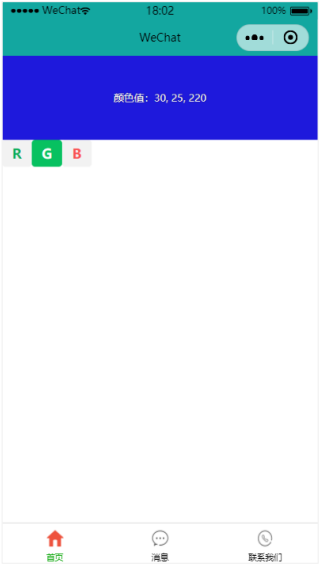

在 `components/test3/test3.js` 中，讲义此阶段的数据名为 `rgb`：

```javascript
Component({
  data: {
    rgb: {
      r: 0,
      g: 0,
      b: 0
    },
    fullColor: '0, 0, 0'
  }
})
```

`rgb` 保存数值，`fullColor` 保存用于渲染的字符串。配套完成版把 `rgb` 改名为 `_rgb`，这是后面“纯数据字段”阶段的改造；当前先按讲义的 `rgb` 阶段理解。

`components/test3/test3.wxml`：

```xml
<view style="background-color: rgb({{fullColor}});" class="colorBox">颜色值：{{fullColor}}</view>
<button size="mini" type="default" bindtap="changeR">R</button>
<button size="mini" type="primary" bindtap="changeG">G</button>
<button size="mini" type="warn" bindtap="changeB">B</button>
```

`components/test3/test3.wxss`：

```css
/* components/test3/test3.wxss */
.colorBox {
  line-height: 200rpx;
  font-size: 24rpx;
  color: white;
  text-shadow: 0rpx 0rpx 2rpx black;
  text-align: center;
}
```

在首页启用 `<my-test3></my-test3>`，应看到颜色块与 R、G、B 三个按钮；初始 `fullColor` 为 `0, 0, 0`，对应黑色。截图是原课案例效果。


### 4. 定义 R、G、B 按钮方法

三个方法均放在 `components/test3/test3.js` 的 `methods` 中。以下按讲义的 `rgb` 命名写，除字段名外与配套完成版保持一致：

```javascript
Component({
  methods: {
    changeR() {
      this.setData({
        'rgb.r': this.data.rgb.r + 5 > 255 ? 255 : this.data.rgb.r + 5
      })
    },
    changeG() {
      this.setData({
        'rgb.g': this.data.rgb.g + 5 > 255 ? 255 : this.data.rgb.g + 5
      })
    },
    changeB() {
      this.setData({
        'rgb.b': this.data.rgb.b + 5 > 255 ? 255 : this.data.rgb.b + 5
      })
    }
  }
})
```

每次点击对应通道增加 `5`，超过 `255` 时固定到 `255`。三个按钮只修改各自的属性，颜色字符串交给监听器统一计算。


### 5. 从指定属性监听到整个对象监听

先按讲义第 25 页，在组件 `observers` 中监听指定属性：

```javascript
Component({
  observers: {
    'rgb.r, rgb.g, rgb.b': function (r, g, b) {
      this.setData({
        fullColor: `${r}, ${g}, ${b}`
      })
    }
  }
})
```

当需要监听的属性较多时，可以用 `**` 通配符监听对象所有属性的变化。讲义随后把上面的监听器换成：

```javascript
Component({
  observers: {
    'rgb.**': function (obj) {
      this.setData({
        fullColor: `${obj.r}, ${obj.g}, ${obj.b}`
      })
    }
  }
})
```

此时回调接收的是整个 `rgb` 对象，而不是三个独立参数。两种写法演示同一计算逻辑，练习时替换监听器即可。

验证顺序：点击 R，再点击 G、B，颜色块和“颜色值”应同时更新；连续点击某通道时，数值不超过 `255`。检查模板字符串中的 `${...}`、逗号以及 WXML 的 `rgb({{fullColor}})` 是否一致。


## 五、纯数据字段

纯数据字段是不用于界面渲染的 `data` 字段。例如，一个字段只供组件内部计算，既不显示在界面上，也不传给其他组件，就适合设置为纯数据字段，以减少不必要的视图更新开销。

在 `Component` 的 `options` 中，用正则表达式 `pureDataPattern` 匹配字段名。讲义示例把所有以下划线开头的字段设为纯数据字段：

```javascript
Component({
  options: {
    pureDataPattern: /^_/
  },
  data: {
    a: true,
    _b: true
  }
})
```

`a` 是普通数据字段，`_b` 匹配 `/^_/`，是纯数据字段。下划线命名本身不会启用这个特性，必须配置 `pureDataPattern`。


### 用纯数据字段改造 RGB 案例

界面实际使用的是 `fullColor`，`rgb` 的三个数值只是计算中间数据。因此把它改名为 `_rgb`，并启用 `/^_/`。

在 `components/test3/test3.js` 中同步改四处：

| 位置 | 改造后的名称 |
| --- | --- |
| `data` 中的对象 | `_rgb` |
| 方法读取 | `this.data._rgb.r`、`.g`、`.b` |
| `setData` 路径 | `'_rgb.r'`、`'_rgb.g'`、`'_rgb.b'` |
| 监听对象 | `'_rgb.**'` |

该阶段的核心代码与配套完成版一致：

```javascript
Component({
  options: {
    pureDataPattern: /^_/
  },

  data: {
    _rgb: {
      r: 0,
      g: 0,
      b: 0
    },
    fullColor: '0, 0, 0'
  },

  methods: {
    changeR() {
      this.setData({
        '_rgb.r': this.data._rgb.r + 5 > 255 ? 255 : this.data._rgb.r + 5
      })
    },
    changeG() {
      this.setData({
        '_rgb.g': this.data._rgb.g + 5 > 255 ? 255 : this.data._rgb.g + 5
      })
    },
    changeB() {
      this.setData({
        '_rgb.b': this.data._rgb.b + 5 > 255 ? 255 : this.data._rgb.b + 5
      })
    }
  },

  observers: {
    '_rgb.**': function (obj) {
      this.setData({
        fullColor: `${obj.r}, ${obj.g}, ${obj.b}`
      })
    }
  }
})
```

`test3.wxml` 与 `test3.wxss` 保持前一节写法。界面只绑定普通字段 `fullColor`，不要改成直接渲染 `_rgb`；纯数据仍可以通过 `setData` 更新并参与监听器计算。

完成后再次点击 R、G、B，颜色块的表现应与改造前一致，区别在于 `_rgb` 不作为视图渲染数据。配套完成版已完成该改造。


## 六、组件的生命周期

组件生命周期描述组件自身从创建、进入页面节点树到移除的过程。原课列出的全部生命周期如下：

| 函数 | 参数 | 执行时机 |
| --- | --- | --- |
| `created` | 无 | 组件实例刚创建 |
| `attached` | 无 | 组件实例进入页面节点树 |
| `ready` | 无 | 组件在视图层布局完成 |
| `moved` | 无 | 组件实例被移动到节点树的另一位置 |
| `detached` | 无 | 组件实例从页面节点树移除 |
| `error` | Error 对象 | 组件方法抛出错误 |

其中本课着重讲三个时机：

1. **`created`**：实例刚创建，不能调用 `setData`；适合给 `this` 添加自定义属性字段。
2. **`attached`**：组件已完成初始化并进入节点树，`this.data` 已初始化；适合进行初始化工作，例如请求初始数据。
3. **`detached`**：组件离开节点树，适合清理工作；退出页面时会触发页面内组件的这个生命周期。

“页面被隐藏”和“组件被移除”是不同状态，不能把切换 tabBar 页面直接当成组件销毁。


### 用 lifetimes 声明组件生命周期

生命周期可以直接放在 `Component` 配置对象的第一级，也可以放在 `lifetimes` 内。**原课推荐 `lifetimes`，相同生命周期同时出现时，`lifetimes` 中的声明优先。**

讲义给出的结构是：

```javascript
Component({
  lifetimes: {
    created() {
      // 在组件实例刚创建时执行
    },
    attached() {
      // 在组件实例进入页面节点树时执行
    },
    detached() {
      // 在组件实例从页面节点树移除时执行
    }
  }
})
```

配套 `test3.js` 保留了创建与挂载的控制台演示，合并到原组件中：

```javascript
Component({
  lifetimes: {
    created() {
      console.log('created ~~~~~')
    },
    attached() {
      console.log('attached ~~~~~')
    }
  }
})
```

在首页启用 `my-test3` 后编译，观察实例创建、挂载时的日志。不要把生命周期函数放进 `methods`，也不要在 `created` 中用 `setData` 更新界面。


## 七、组件所在页面的生命周期

组件的行为有时依赖页面状态。例如，颜色组件应在“页面每次显示时”重新随机生成颜色，而不只在组件首次创建时生成一次。

组件可以通过 `pageLifetimes` 监听所在页面的三个状态：

| 函数 | 参数 | 执行时机 |
| --- | --- | --- |
| `show` | 无 | 所在页面显示 |
| `hide` | 无 | 所在页面隐藏 |
| `resize` | Size 对象 | 所在页面尺寸变化 |

这些名字是组件 `pageLifetimes` 的 `show`、`hide`、`resize`，不是页面 `Page()` 中的 `onShow`、`onHide`，也不是组件 `lifetimes` 的创建和挂载。


### 页面显示时生成随机 RGB 颜色

在 `components/test3/test3.js` 的 `methods` 中添加 `_randomColor`，在 `pageLifetimes.show` 中调用。以下是配套代码的相关节点，需合并到前面的 `_rgb` 组件中：

```javascript
Component({
  methods: {
    _randomColor() {
      this.setData({
        _rgb: {
          r: Math.floor(Math.random() * 256),
          g: Math.floor(Math.random() * 256),
          b: Math.floor(Math.random() * 256)
        }
      })
    }
  },

  pageLifetimes: {
    show() {
      console.log('show')
      this._randomColor()
    },
    hide() {
      console.log('hide')
    },
    resize() {
      console.log('resize')
    }
  }
})
```

`Math.random()` 返回小于 `1` 的非负数，乘以 `256` 后用 `Math.floor` 向下取整，得到 `0～255` 的通道值。这里为整个 `_rgb` 对象赋值，也会触发 `'_rgb.**'` 监听器，进而更新 `fullColor` 和颜色块。

在首页显示颜色组件，然后切换到“消息”或“联系我们”再返回：首页每次显示时应重新生成随机颜色。控制台可用 `show`、`hide` 日志观察页面状态；若当前运行环境发生页面尺寸变化，再观察 `resize`。


## 八、插槽

插槽是在组件 WXML 中预留的 `<slot>` 节点，用来承载组件使用者提供的 WXML 内容。组件决定插槽的位置，使用者决定插入的内容。

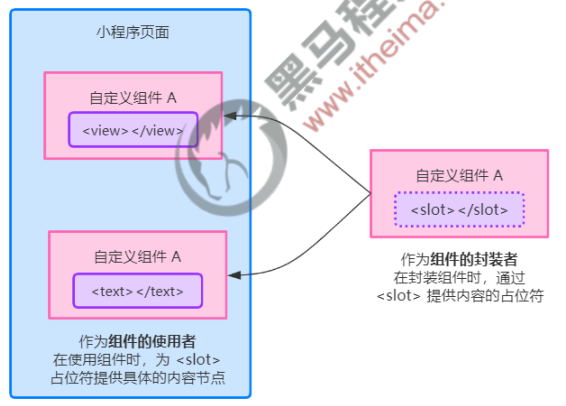

### 1. 单个插槽

默认每个自定义组件只使用一个插槽。按讲义的单个插槽阶段，在 `components/test4/test4.wxml` 提供占位：

```xml
<view>
  <view>这里是组件的内部结构</view>
  <slot></slot>
</view>
```

在 `pages/home/home.wxml` 的组件标签内部填入节点：

```xml
<my-test4>
  <view>这是通过插槽填充的内容</view>
</my-test4>
```

页面应在组件的内部结构后显示传入的 `<view>`。这段内容由使用者提供，不需要写死在组件模板里。


### 2. 启用并使用多个插槽

要在一个组件中预留多个位置，先在 `components/test4/test4.js` 的 `options` 中开启：

```javascript
Component({
  options: {
    multipleSlots: true
  }
})
```

在 `components/test4/test4.wxml` 中，用不同的 `name` 区分插槽。配套完成版为：

```xml
<view>
  <slot name="before"></slot>
  <view>这里是组件的内部结构</view>
  <slot name="after"></slot>
</view>
```

在首页通过 `slot` 属性指定内容应填入哪个位置：

```xml
<my-test4>
  <view slot="before">这是通过插槽填充的内容</view>
  <view slot="after">~~~~~~~</view>
</my-test4>
```

显示顺序应是“这是通过插槽填充的内容”→“这里是组件的内部结构”→“~~~~~~~”。组件中的 `name="before"` 对应使用处的 `slot="before"`，`after` 同理；多个插槽必须先启用 `multipleSlots`。


## 九、父子组件之间的通信

本课把承载子组件的页面也作为“父”来演示。父页面是 `pages/home/home.*`，通信子组件是配套 `components/test5/test5.*`。

| 方式 | 方向与作用 | 本课入口 |
| --- | --- | --- |
| 属性绑定 | 父向子传数据，仅能设置 JSON 兼容数据，不能把方法当作属性传递 | WXML 属性、子组件 `properties` |
| 事件绑定 | 子向父传数据，原课不限定为属性绑定支持的数据类型 | `triggerEvent`、`e.detail` |
| 获取组件实例 | 父直接读取子组件数据或调用方法 | `this.selectComponent()` |

资料差异：讲义后半段的通信标签写成 `my-test3`，配套项目实际使用 `my-test5`；配套的 `test3` 是 RGB 组件。以下统一使用真实的 `my-test5`，与 `app.json` 的引用保持一致。


### 1. 属性绑定：把父页面 count 传给子组件

在 `pages/home/home.js` 定义父页面的计数：

```javascript
Page({
  data: {
    count: 0
  }
})
```

在 `pages/home/home.wxml` 绑定数据：

```xml
<my-test5 count="{{count}}"></my-test5>
<view>父组件中，count值是：{{count}}</view>
```

子组件 `components/test5/test5.js` 必须声明对应属性：

```javascript
Component({
  properties: {
    count: Number
  }
})
```

子组件 `test5.wxml` 使用收到的值：

```xml
<view>子组件中，count值是：{{count}}</view>
```

父页面 `count` 通过绑定传入子组件。初始父子都应显示 `0`；父页面更新计数时，子组件属性跟着绑定更新。


### 2. 事件绑定：子组件把新计数同步给父页面

只修改子组件自身的 `count`，不会自动修改父页面的 `data.count`。本课通过自定义 `sync` 事件把新值送回父页面，按以下四步完成。

**步骤 1：父页面定义处理函数。** 在 `pages/home/home.js` 中先准备 `syncCount(e)`，用于处理子组件发来的事件。

**步骤 2：父页面绑定自定义事件。** 在 `pages/home/home.wxml` 中把 `sync` 与 `syncCount` 关联：

```xml
<my-test5 count="{{count}}" bind:sync="syncCount"></my-test5>
<view>父组件中，count值是：{{count}}</view>
```

讲义说明 `bind:sync="syncCount"` 与 `bindsync="syncCount"` 两种写法都可使用。它建立事件到处理函数的绑定，不是通过 `count` 等属性把函数对象传给子组件。

**步骤 3：子组件触发事件。** 在 `components/test5/test5.js` 中加入按钮方法，先更新自身属性，再发送更新后的数值：

```javascript
Component({
  properties: {
    count: Number
  },

  methods: {
    addCount() {
      this.setData({
        count: this.properties.count + 1
      })
      // 触发自定义事件，将数值同步给父组件
      this.triggerEvent('sync', { value: this.properties.count })
    }
  }
})
```

`components/test5/test5.wxml` 的按钮绑定：

```xml
<view>子组件中，count值是：{{count}}</view>
<button bindtap="addCount">+1</button>
```

`triggerEvent` 第一个参数是事件名 `sync`，第二个参数 `{ value: ... }` 是要传给父页面的事件数据。

**步骤 4：父页面通过 e.detail 取值。** `pages/home/home.js` 的相关代码：

```javascript
Page({
  data: {
    count: 0
  },
  syncCount(e) {
    this.setData({
      count: e.detail.value
    })
  }
})
```

完整过程：子按钮 `addCount` → 子 `count` 加 1 → `triggerEvent('sync', { value })` → 父 `syncCount` 接收 `e.detail.value` → 父 `count` 更新 → 属性绑定继续保持父子一致。

点击子组件按钮后，父子计数应同步增加。若父计数不变，检查事件名 `sync`、绑定函数 `syncCount`、传值字段 `value` 与读取路径 `e.detail.value` 是否一致。


### 3. 获取子组件实例

给首页的子组件添加 `class` 或 `id`，然后在父页面中通过选择器取得实例。`pages/home/home.wxml` 的配套写法：

```xml
<my-test5 count="{{count}}" bind:sync="syncCount" class="customA" id="cA"></my-test5>
<view>~~~~~~~</view>
<view>父组件中，count值是：{{count}}</view>
<button bindtap="getChild">获取子组件的实例对象</button>
```

在父页面 `pages/home/home.js` 中保留 `data`、`syncCount`，并加入配套方法：

```javascript
Page({
  getChild() {
    const child = this.selectComponent('#cA')
    console.log(child)
    // child.setData({
    //   count: child.properties.count + 1
    // })
    child.addCount()
  }
})
```

`this.selectComponent('#cA')` 通过 id 获取实例，也可以用 `this.selectComponent('.customA')`。按照讲义此例的使用要求，传入 id 或 class 选择器，不要用组件标签名代替；组件未匹配时拿不到可调用的实例。

拿到实例后，可以查看 `child.data`、`child.properties`，用 `child.setData` 修改子组件数据，也可以直接调用 `child.addCount()`。

> 配套完成版把直接 `child.setData(...)` 的演示注释掉，只调用 `child.addCount()`，所以一次点击增加 1，并由 `addCount` 内的 `sync` 事件同步父页面。直接调用 `setData` 本身不会触发这个自定义事件；若同时打开注释中的更新和 `addCount()`，子计数会增加两次。

验证时点击“获取子组件的实例对象”，控制台应能查看实例，父子计数应同时增加。


## 十、behaviors

`behaviors` 是小程序实现组件间代码共享的机制，原课类比 Vue 的 mixins：把多个组件都需要的属性、数据、方法或生命周期组织为可复用的一组定义。

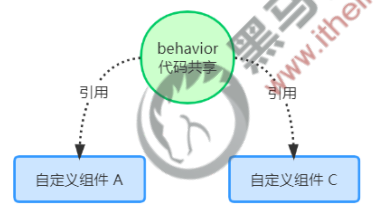

每个组件可以引用多个 behavior，behavior 也可以引用其他 behavior。组件引用后，相关定义会合并到组件中。这里共享的是组件定义中的代码和初始数据，不应把它理解为两个实例共享一个实时联动的计数状态。


### 1. 创建、导出并引用 behavior

在项目根目录建立 `behaviors/my-behavior.js`，调用 `Behavior()` 创建并通过 `module.exports` 导出。配套文件内容：

```javascript
module.exports = Behavior({
  data: {
    username: 'zs'
  },
  properties: {},
  methods: {}
})
```

在 `components/test5/test5.js` 通过 `require` 导入，再放入 `behaviors` 数组。下面保留配套完成版的属性、数据和方法，可与上一节通信练习一起使用：

```javascript
// components/test5/test5.js
const myBehavior = require('../../behaviors/my-behavior')

Component({
  behaviors: [myBehavior],
  /**
   * 组件的属性列表
   */
  properties: {
    count: Number
  },

  /**
   * 组件的初始数据
   */
  data: {
    username: 'ls'
  },

  /**
   * 组件的方法列表
   */
  methods: {
    addCount() {
      this.setData({
        count: this.properties.count + 1
      })
      // 触发自定义事件，将数值同步给父组件
      this.triggerEvent('sync', { value: this.properties.count })
    }
  }
})
```

`../../behaviors/my-behavior` 是相对于 `components/test5/test5.js` 的路径；先回到小程序根目录，再进入 `behaviors`。导入模块后要挂载到 `behaviors: [myBehavior]`，不能只写 `require`。

配套 `test5.wxml` 同时展示计数和用户名：

```xml
<!--components/test5/test5.wxml-->
<view>子组件中，count值是：{{count}}</view>
<button bindtap="addCount">+1</button>
<view>在behavior中定义的用户名是：{{username}}</view>
```

behavior 的 `username` 为 `zs`，但组件自己的 `data.username` 为 `ls`，所以完成版应显示 `ls`。若只保留 behavior 的定义、移除组件自身的同名 `username` 字段，则可以观察共享定义提供的 `zs`。这正是配套代码演示同名字段覆盖的地方。


### 2. behavior 可用节点与同名字段

讲义列出的可用节点均非必填：

| 节点 | 用途 |
| --- | --- |
| `properties` | 定义组件属性 |
| `data` | 定义组件初始数据 |
| `methods` | 定义组件方法 |
| `behaviors` | 引用其他 behavior |
| `created`、`attached`、`ready`、`moved`、`detached` | 定义对应生命周期函数 |

资料校对：讲义表格把 `behaviors` 的类型写成 `String Array`，但同一讲义的用法和配套源码都是 `behaviors: [myBehavior]`，数组中放的是导入的 behavior 实例。本篇按实际调用写法保留。

组件和它引用的 behavior 可能出现同名定义。原课提醒分清三类规则：

1. 同名的 `data` 数据字段。
2. 同名的 `properties` 属性或 `methods` 方法。
3. 同名的生命周期函数。

本天正文没有逐条展开所有组合情况，而是给出[官方 behaviors 文档](https://developers.weixin.qq.com/miniprogram/dev/framework/custom-component/behaviors.html)供查阅。当前示例先确认组件自身的 `username: 'ls'` 覆盖 behavior 的 `username: 'zs'`，不要把这个单字段结果直接推广到全部节点。


## 十一、原课学习目标与练习检查

原课最后的六项学习目标是：

| 学习目标 | 对应关键写法 |
| --- | --- |
| 创建并引用组件 | `Component()`、`"component": true`、`usingComponents`、局部/全局引用 |
| 修改样式隔离选项 | `options.styleIsolation`：`isolated`、`apply-shared`、`shared` |
| 定义和使用数据监听器 | `observers`、逗号分隔字段、对象属性路径与 `**` |
| 定义和使用纯数据字段 | `options.pureDataPattern`、`/^_/`、`_rgb` |
| 掌握父子通信的三种方式 | 属性绑定、事件绑定、`this.selectComponent()` |
| 定义并使用 behaviors | `Behavior()`、`module.exports`、`require()`、`behaviors` 数组 |

按练习过程检查：

1. **组件引用**：开启对应组件标签，页面能显示内容；第一组路径使用 `/components/test/test`。
2. **样式隔离**：对照默认隔离与 `shared`，观察相同类名的文字颜色；避免把完成版 `shared` 当成默认状态。
3. **数据与属性**：先练固定 `max` 的计数限制，再观察完成版同时更新 `count`、`max` 的效果。
4. **数据监听与纯数据字段**：求和与 RGB 色块随按钮更新；改为 `_rgb` 后所有读取路径及监听路径一起更新，界面仍只绑定 `fullColor`。
5. **生命周期**：区分组件创建/挂载与页面显示/隐藏；返回首页时生成随机颜色，`created` 中不调用 `setData`。
6. **插槽**：单插槽能显示传入节点；多插槽按 `before`、内部结构、`after` 的顺序显示。
7. **父子通信**：子按钮通过 `sync` 事件同步父计数；父页面用 `#cA` 取得实例并调用 `addCount`，计数仍保持一致。
8. **behavior**：挂载共享定义后可用 `username`，完成版同名字段取组件自己的 `ls`。

这些是运行配套项目时的预期验证步骤。本笔记已依据原讲义和源码整理，尚未在微信开发者工具中实际运行案例。
